# Análise da Imagética Motora (MIQ-3) e Correlações Multimodais

Exploração da capacidade de Imagética Motora (Visual Interna, Visual Externa e Cinestésica) avaliada pelo MIQ-3.

**Estratégia Analítica:**
1. **Estatística Descritiva e Inferencial:** Caracterização dos scores por grupo (A - Atletas, AB - Futebolistas, C - Não-Federados) e comparação não-paramétrica (Mann-Whitney U) devido à natureza ordinal do instrumento.
2. **Visualização:** Construção de *Boxplots* para ilustrar a dispersão do score total de imagética motora.
3. **Correlações Cérebro-Comportamento-Imagética:** Teste de correlações de Spearman entre as dimensões do MIQ-3, o desempenho comportamental e a ativação hemodinâmica (HbO) nas tarefas de Stroop e Decision Making.

--- Estatística Descritiva: MIQ-3 ---


Score IVI MIQ-3                    Score IVE MIQ-3  \
                                 mean   std median count            mean   
Grupo_Análise                                                              
A (Atletas Coletivos)           22.96  2.71   23.5    28           23.00   
AB (Futebolistas)               23.45  2.77   24.0    22           23.32   
C (Não-Federados)               22.57  3.57   22.0    23           22.22   

                                         Score IC MIQ-3                     \
                        std median count           mean   std median count   
Grupo_Análise                                                                
A (Atletas Coletivos)  3.20   23.5    28          21.61  3.96   22.0    28   
AB (Futebolistas)      3.01   24.0    22          22.18  3.33   22.0    22   
C (Não-Federados)      3.32   21.0    23          21.04  4.73   22.0    23   

                      MIQ-3 Total                      
                             mean    std median count  
Grupo_Análise                                          
A (Atletas Coletivos)       67.57   7.97   68.0    28  
AB (Futebolistas)           68.95   6.74   68.0    22  
C (Não-Federados)           65.83  10.55   65.0    23


--- Inferência Estatística (Mann-Whitney U) ---


,Variável,Comparação,U,p-val,RBC (Efeito),Significativo
0,Score IVI MIQ-3,A vs C,341.0,0.7247,0.0590,False
1,Score IVI MIQ-3,AB vs C,290.0,0.4047,0.1462,False
2,Score IVE MIQ-3,A vs C,362.0,0.4520,0.1242,False
3,Score IVE MIQ-3,AB vs C,300.5,0.2825,0.1877,False
4,Score IC MIQ-3,A vs C,337.5,0.7751,0.0481,False
5,Score IC MIQ-3,AB vs C,279.5,0.5522,0.1047,False
6,MIQ-3 Total,A vs C,357.5,0.5071,0.1102,False
7,MIQ-3 Total,AB vs C,303.5,0.2554,0.1996,False



Boxplot exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Comportamentais_MIQ3\Boxplot_MIQ3_Total.png


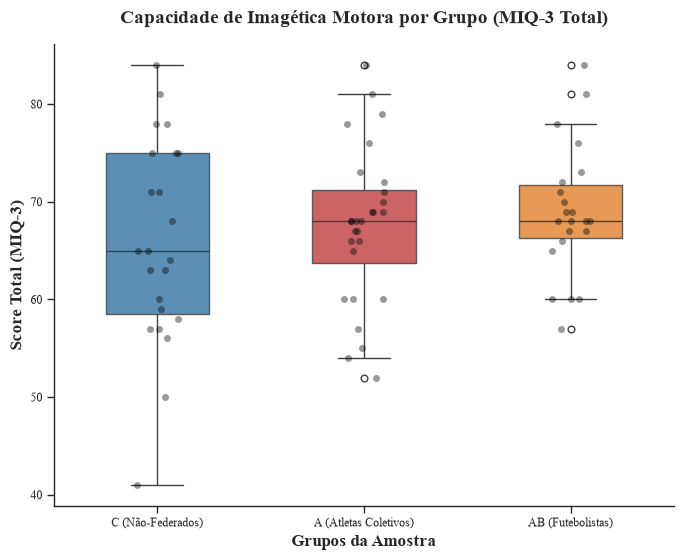


--- A calcular Matrizes de Correlação (Imagética vs Cérebro/Comportamento) ---

[!] Top Correlações Relevantes na tarefa de Stroop:


,MIQ_Var,Alvo,Rho,p-val
172,Score IC MIQ-3,HbO_S8_D6_Con_Beta,-0.3525,0.0121
131,Score IC MIQ-3,HbO_S2_D3_Inc-Con_Beta,0.3397,0.0158
154,Score IC MIQ-3,HbO_S5_D6_Con_Beta,-0.2927,0.0391
232,MIQ-3 Total,HbO_S8_D6_Con_Beta,-0.2842,0.0455
112,Score IVE MIQ-3,HbO_S8_D6_Con_Beta,-0.2826,0.0468



[!] Top Correlações Relevantes na tarefa de Decision Making:


,MIQ_Var,Alvo,Rho,p-val
79,MIQ-3 Total,HbO_S3_D2_Beta,0.5250,0.0006
59,Score IC MIQ-3,HbO_S3_D2_Beta,0.4886,0.0016
21,Score IVE MIQ-3,HbO_S1_D2_Beta,0.4444,0.0032
39,Score IVE MIQ-3,HbO_S3_D2_Beta,0.4277,0.0066
22,Score IVE MIQ-3,HbO_S2_D1_Beta,0.3770,0.0064
19,Score IVI MIQ-3,HbO_S3_D2_Beta,0.3512,0.0283
65,MIQ-3 Total,HbO_S3_D4_Beta,0.3398,0.0158
25,Score IVE MIQ-3,HbO_S3_D4_Beta,0.3293,0.0195
61,MIQ-3 Total,HbO_S1_D2_Beta,0.3105,0.0453
33,Score IVE MIQ-3,HbO_S6_D5_Beta,0.3099,0.0321



Pipeline MIQ-3 concluído com sucesso!


In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configurações e Leitura de Dados
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Comportamentais_MIQ3"
pasta_resultados.mkdir(parents=True, exist_ok=True)

caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"
df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset" if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names else 0)

# ==========================================================
# 2. Definição da Amostra Analítica e Grupos
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
else:
    is_individual = (~df_demo['Modalidade'].isin(mods_coletivas))

individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
df_analitica = df_demo.drop(individuais).copy()

df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C (Não-Federados)'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A (Atletas Coletivos)'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A (Atletas Coletivos)') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB (Futebolistas)'

# Criar dataframe maestro com duplicação do AB para visualização/descritivas lado a lado
df_master_grupos = pd.concat([df_analitica, df_fut], ignore_index=True)

# ----------------------------------------------------------
# CORREÇÃO DINÂMICA DAS COLUNAS DO MIQ-3
# ----------------------------------------------------------
# Limpar espaços invisíveis no início/fim dos nomes de todas as colunas
df_master_grupos.columns = df_master_grupos.columns.str.strip()
df_analitica.columns = df_analitica.columns.str.strip()
df_fut.columns = df_fut.columns.str.strip()

# Detetar as colunas automaticamente (ignorando falhas exatas de texto)
col_ivi = [c for c in df_master_grupos.columns if 'Score IVI' in c][0]
col_ive = [c for c in df_master_grupos.columns if 'Score IVE' in c][0]
col_ic = [c for c in df_master_grupos.columns if 'Score IC' in c][0]
col_total = [c for c in df_master_grupos.columns if 'MIQ-3 Total' in c or ('Total' in c and 'MIQ' in c)][0]

vars_miq = [col_ivi, col_ive, col_ic, col_total]

# Forçar numéricos nas colunas MIQ-3 com a formatação correta
for var in vars_miq:
    df_master_grupos[var] = pd.to_numeric(df_master_grupos[var].astype(str).str.replace(',', '.'), errors='coerce')
    df_analitica[var] = pd.to_numeric(df_analitica[var].astype(str).str.replace(',', '.'), errors='coerce')
    df_fut[var] = pd.to_numeric(df_fut[var].astype(str).str.replace(',', '.'), errors='coerce')

# ==========================================================
# 3. Estatística Descritiva
# ==========================================================
print("--- Estatística Descritiva: MIQ-3 ---")
desc_miq = df_master_grupos.groupby('Grupo_Análise')[vars_miq].agg(['mean', 'std', 'median', 'count']).round(2)
display(desc_miq)

ficheiro_desc = pasta_resultados / "Descritivas_MIQ3_Por_Grupo.xlsx"
desc_miq.to_excel(ficheiro_desc)

# ==========================================================
# 4. Estatística Inferencial (Mann-Whitney U: A vs C e AB vs C)
# ==========================================================
print("\n--- Inferência Estatística (Mann-Whitney U) ---")
resultados_mwu = []

for var in vars_miq:
    # A vs C
    xA = df_analitica.loc[df_analitica['Grupo_Análise'] == 'A (Atletas Coletivos)', var].dropna()
    xC = df_analitica.loc[df_analitica['Grupo_Análise'] == 'C (Não-Federados)', var].dropna()
    if len(xA) > 0 and len(xC) > 0:
        mwu_A_C = pg.mwu(xA, xC)
        # Usar as colunas originais do dataframe gerado pelo pingouin (independentemente do nome)
        u_val = mwu_A_C.iloc[0]['U-val'] if 'U-val' in mwu_A_C.columns else mwu_A_C.iloc[0, 0]
        p_val = mwu_A_C.iloc[0]['p-val'] if 'p-val' in mwu_A_C.columns else mwu_A_C.iloc[0, 2] # P-val costuma ser a 3ª coluna
        rbc = mwu_A_C.iloc[0]['RBC'] if 'RBC' in mwu_A_C.columns else mwu_A_C.iloc[0, 3] # RBC costuma ser a 4ª coluna
        
        resultados_mwu.append({'Variável': var, 'Comparação': 'A vs C', 'U': u_val, 'p-val': p_val, 'RBC (Efeito)': rbc})
        
    # AB vs C
    xAB = df_fut.loc[df_fut['Grupo_Análise'] == 'AB (Futebolistas)', var].dropna()
    if len(xAB) > 0 and len(xC) > 0:
        mwu_AB_C = pg.mwu(xAB, xC)
        u_val = mwu_AB_C.iloc[0]['U-val'] if 'U-val' in mwu_AB_C.columns else mwu_AB_C.iloc[0, 0]
        p_val = mwu_AB_C.iloc[0]['p-val'] if 'p-val' in mwu_AB_C.columns else mwu_AB_C.iloc[0, 2]
        rbc = mwu_AB_C.iloc[0]['RBC'] if 'RBC' in mwu_AB_C.columns else mwu_AB_C.iloc[0, 3]
        
        resultados_mwu.append({'Variável': var, 'Comparação': 'AB vs C', 'U': u_val, 'p-val': p_val, 'RBC (Efeito)': rbc})

df_mwu = pd.DataFrame(resultados_mwu)
if not df_mwu.empty:
    df_mwu['Significativo'] = df_mwu['p-val'] < 0.05
    display(df_mwu.round(4))
    df_mwu.to_excel(pasta_resultados / "Inferencia_MIQ3_MannWhitney.xlsx", index=False)
else:
    print("[Aviso] Não foi possível calcular a estatística de Mann-Whitney. Verifica os dados.")

# ==========================================================
# 5. Visualização (Boxplot do Score Total)
# ==========================================================
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

plt.figure(figsize=(8, 6))
cores = {'A (Atletas Coletivos)': '#d62728', 'AB (Futebolistas)': '#ff7f0e', 'C (Não-Federados)': '#1f77b4'}

ax = sns.boxplot(data=df_master_grupos, x='Grupo_Análise', y=col_total, palette=cores, width=0.5, boxprops=dict(alpha=0.8))
sns.stripplot(data=df_master_grupos, x='Grupo_Análise', y=col_total, color='black', alpha=0.4, jitter=True, size=5)

plt.title("Capacidade de Imagética Motora por Grupo (MIQ-3 Total)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Grupos da Amostra", fontsize=12, fontweight='bold')
plt.ylabel("Score Total (MIQ-3)", fontsize=12, fontweight='bold')
sns.despine()

caminho_figura = pasta_resultados / "Boxplot_MIQ3_Total.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')
print(f"\nBoxplot exportado para: {caminho_figura.resolve()}")
plt.show()

# ==========================================================
# 6. Correlações com Desempenho e Cérebro (Stroop & DM)
# ==========================================================
print("\n--- A calcular Matrizes de Correlação (Imagética vs Cérebro/Comportamento) ---")
from scipy.stats import spearmanr

def extrair_correlacoes(tarefa, ficheiro_fNIRS, vars_comp):
    caminho_nirs = pasta_dados / ficheiro_fNIRS
    if caminho_nirs.suffix == '.csv':
        df_nirs = pd.read_csv(caminho_nirs, sep=';', decimal=',')
        if len(df_nirs.columns) < 5: df_nirs = pd.read_csv(caminho_nirs, sep=',', decimal='.')
    else:
        df_nirs = pd.read_excel(caminho_nirs)
        
    df_nirs.columns = df_nirs.columns.str.strip()
    df_nirs['ID_Clean'] = df_nirs.iloc[:, 0].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
    
    # Merge com os dados do MIQ-3 da amostra analítica principal
    df_corr = pd.merge(df_analitica[['ID_Clean'] + vars_miq], df_nirs, on='ID_Clean', how='inner')
    
    canais_hbo = [col for col in df_nirs.columns if col.startswith('HbO_') and col.endswith('_Beta')]
    vars_alvo = vars_comp + canais_hbo
    
    for var in vars_miq + vars_alvo:
        if var in df_corr.columns:
            df_corr[var] = pd.to_numeric(df_corr[var].astype(str).str.replace(',', '.'), errors='coerce')
            
    df_corr = df_corr.dropna(subset=vars_miq)
    
    resultados_corr = []
    for var_miq in vars_miq:
        for var_alvo in vars_alvo:
            if var_alvo in df_corr.columns:
                df_temp = df_corr[[var_miq, var_alvo]].dropna()
                if len(df_temp) > 10:
                    # Usar scipy em vez de pingouin para evitar KeyErrors das versões
                    rho, pval = spearmanr(df_temp[var_miq], df_temp[var_alvo])
                    resultados_corr.append({'MIQ_Var': var_miq, 'Alvo': var_alvo, 'Rho': rho, 'p-val': pval})
                    
    df_res = pd.DataFrame(resultados_corr)
    
    if df_res.empty:
        print(f"\n[i] Nenhuma correlação calculada para a tarefa de {tarefa}.")
        return
        
    # Mostrar as correlações com p-value < 0.05 ou moderadas/fortes (absoluto >= 0.30)
    df_sig = df_res[(df_res['p-val'] < 0.05) | (df_res['Rho'].abs() >= 0.30)].sort_values(by='Rho', key=abs, ascending=False)
    
    if not df_sig.empty:
        print(f"\n[!] Top Correlações Relevantes na tarefa de {tarefa}:")
        display(df_sig.head(10).round(4))
        df_sig.to_excel(pasta_resultados / f"Correlacoes_MIQ3_vs_{tarefa}.xlsx", index=False)
    else:
        print(f"\n[i] Nenhuma correlação moderada/significativa encontrada na tarefa de {tarefa}.")

# Executar correlações
extrair_correlacoes("Stroop", "dataset_FINAL_SPA_fNIRS_Stroop.csv", ['ST_Acc_N_Total', 'ST_RT_Medio_Total_seg'])
extrair_correlacoes("Decision Making", "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv", ['DM_Acc_N_Total', 'DM_RT_Medio_Total_seg'])

print("\nPipeline MIQ-3 concluído com sucesso!")

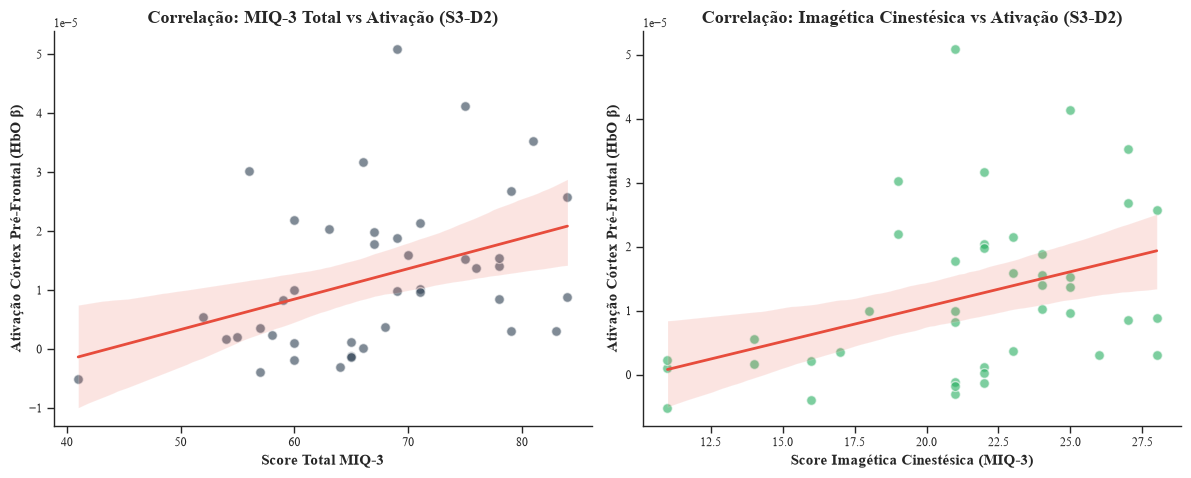

Painel de Scatter Plots exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Comportamentais_MIQ3\ScatterPlots_MIQ3_DecisionMaking.png


In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# 1. Configurações e Dados
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Comportamentais_MIQ3"
plt.rcParams['font.family'] = 'Times New Roman'

# Carregar Dados do DM (onde tens a correlação mais forte)
caminho_dm = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# Carregar o MIQ-3 a partir do Merge
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"
df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset" if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names else 0)

# Limpeza e Merge (exatamente como no script anterior)
df_dm['ID_Clean'] = df_dm.iloc[:, 0].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_demo['ID_Clean'] = df_demo.iloc[:, 0].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

col_ic = [c for c in df_demo.columns if 'Score IC' in c][0]
col_total = [c for c in df_demo.columns if 'MIQ-3 Total' in c or ('Total' in c and 'MIQ' in c)][0]

df_corr = pd.merge(df_demo[['ID_Clean', col_ic, col_total]], df_dm[['ID_Clean', 'HbO_S3_D2_Beta']], on='ID_Clean', how='inner')

for col in [col_ic, col_total, 'HbO_S3_D2_Beta']:
    df_corr[col] = pd.to_numeric(df_corr[col].astype(str).str.replace(',', '.'), errors='coerce')

df_corr = df_corr.dropna()

# 2. Desenhar os Scatter Plots (Painel 1x2)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.set_theme(style="ticks", context="paper")

# Plot 1: MIQ-3 Total vs Ativação (A correlação fenomenal de Rho = 0.525)
sns.regplot(
    data=df_corr, x=col_total, y='HbO_S3_D2_Beta', 
    ax=axes[0], color='#2c3e50',
    scatter_kws={'alpha':0.6, 's':50, 'edgecolor': 'w'}, 
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)
axes[0].set_title('Correlação: MIQ-3 Total vs Ativação (S3-D2)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Score Total MIQ-3', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Ativação Córtex Pré-Frontal (HbO \u03B2)', fontsize=11, fontweight='bold')

# Plot 2: Imagética Cinestésica vs Ativação (Rho = 0.488)
sns.regplot(
    data=df_corr, x=col_ic, y='HbO_S3_D2_Beta', 
    ax=axes[1], color='#27ae60',
    scatter_kws={'alpha':0.6, 's':50, 'edgecolor': 'w'}, 
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)
axes[1].set_title('Correlação: Imagética Cinestésica vs Ativação (S3-D2)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Score Imagética Cinestésica (MIQ-3)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Ativação Córtex Pré-Frontal (HbO \u03B2)', fontsize=11, fontweight='bold')

sns.despine()
plt.tight_layout()

caminho_plot = pasta_resultados / "ScatterPlots_MIQ3_DecisionMaking.png"
plt.savefig(caminho_plot, dpi=300, bbox_inches='tight')
plt.show()
print(f"Painel de Scatter Plots exportado para: {caminho_plot.resolve()}")

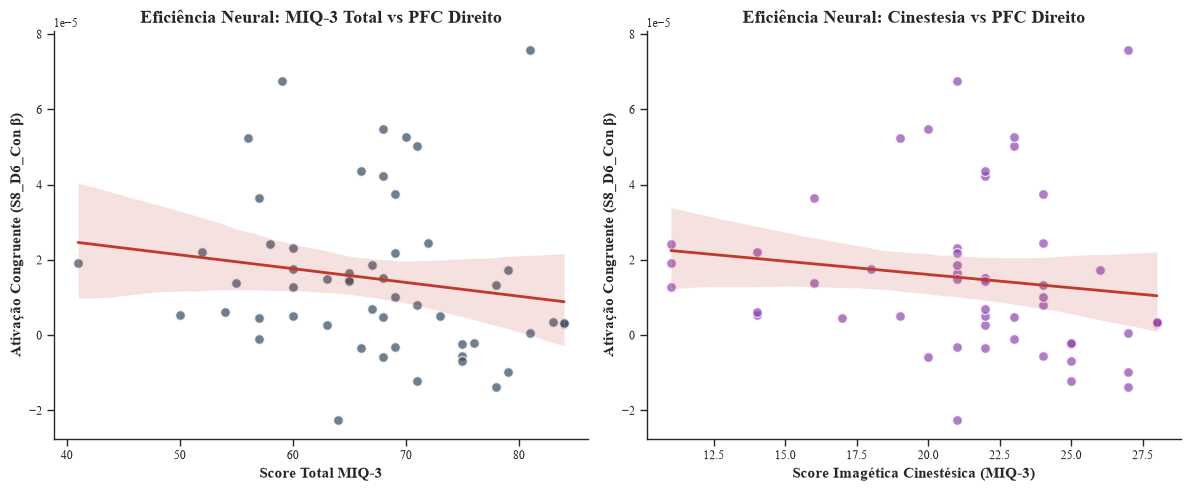

Painel de Scatter Plots (Stroop) exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Comportamentais_MIQ3\ScatterPlots_MIQ3_Stroop.png


In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configurações e Dados (Tarefa Stroop)
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Comportamentais_MIQ3"
plt.rcParams['font.family'] = 'Times New Roman'

# Carregar Dados do Stroop
caminho_stroop = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5: df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# Carregar o MIQ-3 a partir do Merge
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"
df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset" if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names else 0)

# Limpeza de IDs
df_stroop['ID_Clean'] = df_stroop.iloc[:, 0].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_demo['ID_Clean'] = df_demo.iloc[:, 0].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

# Identificação Dinâmica das Colunas MIQ-3
col_ic = [c for c in df_demo.columns if 'Score IC' in c][0]
col_total = [c for c in df_demo.columns if 'MIQ-3 Total' in c or ('Total' in c and 'MIQ' in c)][0]

# O alvo no Stroop será o canal mais significativo: HbO_S8_D6_Con_Beta
canal_alvo_stroop = 'HbO_S8_D6_Con_Beta'

# Merge dos Datasets
df_corr_st = pd.merge(df_demo[['ID_Clean', col_ic, col_total]], df_stroop[['ID_Clean', canal_alvo_stroop]], on='ID_Clean', how='inner')

# Converter para numérico
for col in [col_ic, col_total, canal_alvo_stroop]:
    df_corr_st[col] = pd.to_numeric(df_corr_st[col].astype(str).str.replace(',', '.'), errors='coerce')

df_corr_st = df_corr_st.dropna()

# ==========================================================
# 2. Desenhar os Scatter Plots (Painel 1x2 - Stroop)
# ==========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

# Para contrastar com os tons quentes/verdes do DM, usamos tons frios (azuis/roxos) para a eficiência neural
cor_pontos_total = '#34495e'
cor_pontos_ic = '#8e44ad'
cor_linha = '#c0392b'

# Plot 1: MIQ-3 Total vs Ativação Stroop
sns.regplot(
    data=df_corr_st, x=col_total, y=canal_alvo_stroop, 
    ax=axes[0], color=cor_pontos_total,
    scatter_kws={'alpha':0.7, 's':50, 'edgecolor': 'w'}, 
    line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[0].set_title(f'Eficiência Neural: MIQ-3 Total vs PFC Direito', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Score Total MIQ-3', fontsize=11, fontweight='bold')
axes[0].set_ylabel(f'Ativação Congruente ({canal_alvo_stroop.replace("_Beta", "").replace("HbO_", "")} \u03B2)', fontsize=11, fontweight='bold')

# Plot 2: Imagética Cinestésica vs Ativação Stroop (A correlação negativa de Rho = -0.35)
sns.regplot(
    data=df_corr_st, x=col_ic, y=canal_alvo_stroop, 
    ax=axes[1], color=cor_pontos_ic,
    scatter_kws={'alpha':0.7, 's':50, 'edgecolor': 'w'}, 
    line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[1].set_title(f'Eficiência Neural: Cinestesia vs PFC Direito', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Score Imagética Cinestésica (MIQ-3)', fontsize=11, fontweight='bold')
axes[1].set_ylabel(f'Ativação Congruente ({canal_alvo_stroop.replace("_Beta", "").replace("HbO_", "")} \u03B2)', fontsize=11, fontweight='bold')

sns.despine()
plt.tight_layout()

caminho_plot_st = pasta_resultados / "ScatterPlots_MIQ3_Stroop.png"
plt.savefig(caminho_plot_st, dpi=300, bbox_inches='tight')
plt.show()
print(f"Painel de Scatter Plots (Stroop) exportado para: {caminho_plot_st.resolve()}")